# Gradient Boosting

**Member:** IT24102310 - Jayawardena H.S.P.P  
**Project:** IT3091 Telco Customer Churn

Build, tune, and evaluate the Gradient Boosting model.

## 1. Imports and paths

Gradient Boosting is tree-based, so numerical scaling is not required. Preprocessing is handled by the shared pipeline.

In [1]:
# IT3091 - Telco Customer Churn
# Gradient Boosting Model Development
# Member: IT24102310 - Jayawardena H.S.P.P

import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve
)
from sklearn.model_selection import GridSearchCV, cross_val_predict

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_preparation import load_and_clean_data, separate_features_target
from src.evaluation import evaluate_cv
from src.imbalance import build_model_pipeline
from src.validation import create_train_test_split, get_cross_validation

TABLE_PATH = project_root / "results" / "tables" / "gradient_boosting_standard_cv.csv"
FIGURE_DIR = project_root / "results" / "figures" / "gradient_boosting"
MODEL_PATH = project_root / "results" / "models" / "gradient_boosting.joblib"

TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
print("Project root:", project_root)

Project root: C:\Users\sadee\Documents\Y3S1\ML\Project\New folder\IT3091_Telco_Churn--2


## 2. Load data and create the shared split

Use the same stratified 80/20 split as the other models. The test set is not used in this notebook.

In [2]:
df = load_and_clean_data(project_root)
X, y = separate_features_target(df)
X_train, X_test, y_train, y_test = create_train_test_split(X, y)

assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)

split_summary = pd.DataFrame({
    "Split": ["Training", "Held-out test"],
    "Records": [len(X_train), len(X_test)],
    "Churn rate": [y_train.mean(), y_test.mean()]
})
split_summary_display = split_summary.copy()
split_summary_display["Churn rate"] = split_summary_display["Churn rate"].map("{:.2%}".format)
display(split_summary_display)
print("Predictor columns before pipeline preprocessing:", X_train.shape[1])

,Split,Records,Churn rate
0,Training,5634,26.54%
1,Held-out test,1409,26.54%


Predictor columns before pipeline preprocessing: 19


## 3. Build and tune the model

Tune the learning rate, number of estimators, tree depth, and random oversampling. `TenureGroup` and `ServiceCount` are included through the shared pipeline.

In [3]:
gb_pipeline = build_model_pipeline(
    model=GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        min_samples_leaf=10
    ),
    scale_numeric=False,
    add_engineered_features=True,
    imbalance_strategy="random_oversampling"
)

param_grid = {
    "sampler": [
        "passthrough",
        RandomOverSampler(random_state=RANDOM_STATE)
    ],
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.10],
    "model__max_depth": [2, 3]
}

tuned_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=get_cross_validation(),
    refit=True,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

candidate_count = int(np.prod([len(values) for values in param_grid.values()]))
print("Pipeline steps:", list(gb_pipeline.named_steps.keys()))
print("Hyperparameter candidates:", candidate_count)
print("Inner validation folds per candidate:", get_cross_validation().n_splits)

Pipeline steps: ['features', 'preprocessor', 'sampler', 'model']
Hyperparameter candidates: 16
Inner validation folds per candidate: 5


## 4. Tune with standard 5-fold cross-validation

Use the shared stratified five-fold strategy to choose the best hyperparameters using training data only.

In [4]:
tuned_search.fit(X_train, y_train)
best_pipeline = tuned_search.best_estimator_

print("Best 5-fold CV F1:", round(tuned_search.best_score_, 4))
print("Best parameters:")
for parameter, value in tuned_search.best_params_.items():
    print(f"  {parameter}: {value}")

tuning_summary = (
    pd.DataFrame(tuned_search.cv_results_)
    .loc[:, ["rank_test_score", "mean_test_score", "std_test_score", "params"]]
    .sort_values("rank_test_score")
    .head(10)
)
display(tuning_summary)

Best 5-fold CV F1: 0.6359
Best parameters:
  model__learning_rate: 0.05
  model__max_depth: 2
  model__n_estimators: 200
  sampler: RandomOverSampler(random_state=42)


,rank_test_score,mean_test_score,std_test_score,params
3,1,0.635937,0.016413,"{'model__learning_rate': 0.05, 'model__max_dep..."
9,2,0.635842,0.016022,"{'model__learning_rate': 0.1, 'model__max_dept..."
13,3,0.634062,0.017074,"{'model__learning_rate': 0.1, 'model__max_dept..."
11,4,0.633134,0.012548,"{'model__learning_rate': 0.1, 'model__max_dept..."
15,5,0.630630,0.018686,"{'model__learning_rate': 0.1, 'model__max_dept..."
5,6,0.630517,0.019910,"{'model__learning_rate': 0.05, 'model__max_dep..."
7,7,0.629472,0.014816,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,8,0.628226,0.016062,"{'model__learning_rate': 0.05, 'model__max_dep..."
10,9,0.592255,0.020506,"{'model__learning_rate': 0.1, 'model__max_dept..."
12,10,0.591627,0.023555,"{'model__learning_rate': 0.1, 'model__max_dept..."


In [5]:
gb_standard_cv = evaluate_cv(
    best_pipeline,
    X_train,
    y_train
)

gb_standard_cv.to_csv(TABLE_PATH, index=False)
display(gb_standard_cv)
print("Saved standard CV metrics to:", TABLE_PATH)

,Metric,Mean,Std
0,F1,0.6359,0.0164
1,Recall,0.8074,0.0255
2,Precision,0.5248,0.0153
3,ROC_AUC,0.8490,0.0127
4,Accuracy,0.7547,0.0118


Saved standard CV metrics to: C:\Users\sadee\Documents\Y3S1\ML\Project\New folder\IT3091_Telco_Churn--2\results\tables\gradient_boosting_standard_cv.csv


## 5. Fit and save the selected model

Save the fitted pipeline selected by standard five-fold cross-validation.

In [6]:
joblib.dump(best_pipeline, MODEL_PATH)
print("Saved fitted Gradient Boosting pipeline to:", MODEL_PATH)

Saved fitted Gradient Boosting pipeline to: C:\Users\sadee\Documents\Y3S1\ML\Project\New folder\IT3091_Telco_Churn--2\results\models\gradient_boosting.joblib


In [7]:
print("Saved pipeline steps:", list(best_pipeline.named_steps.keys()))
print("Selected estimator:", best_pipeline.named_steps["model"])
print("Selected sampler:", best_pipeline.named_steps["sampler"])

Saved pipeline steps: ['features', 'preprocessor', 'sampler', 'model']
Selected estimator: GradientBoostingClassifier(learning_rate=0.05, max_depth=2, min_samples_leaf=10,
                           n_estimators=200, random_state=42)
Selected sampler: RandomOverSampler(random_state=42)


### Standard 5-fold CV results

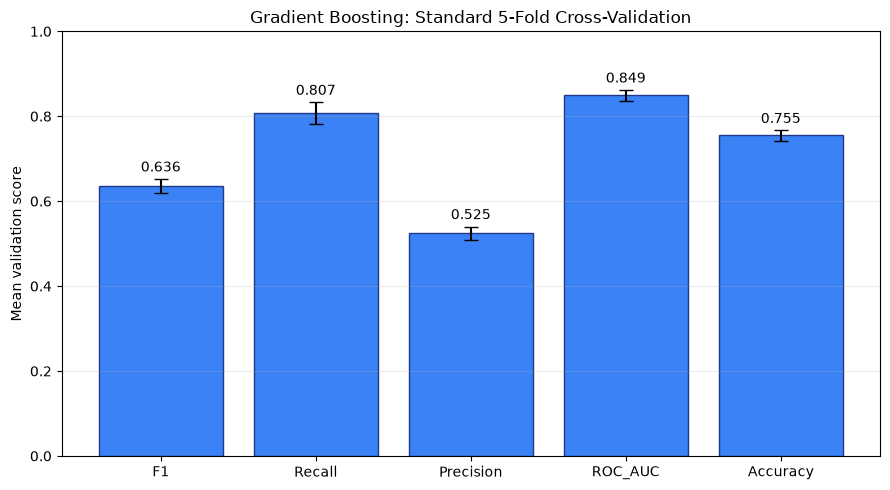

Saved metric figure to: C:\Users\sadee\Documents\Y3S1\ML\Project\New folder\IT3091_Telco_Churn--2\results\figures\gradient_boosting\cv_metrics.png


In [8]:
plot_data = gb_standard_cv.copy()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    plot_data["Metric"],
    plot_data["Mean"],
    yerr=plot_data["Std"],
    capsize=5,
    color="#3B82F6",
    edgecolor="#1E3A8A"
)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in plot_data["Mean"]], padding=3)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Mean validation score")
ax.set_title("Gradient Boosting: Standard 5-Fold Cross-Validation")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
metrics_figure_path = FIGURE_DIR / "cv_metrics.png"
fig.savefig(metrics_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved metric figure to:", metrics_figure_path)

## 6. Cross-validated predictions

Create out-of-fold predictions from the training set for the confusion matrix and precision-recall curve.

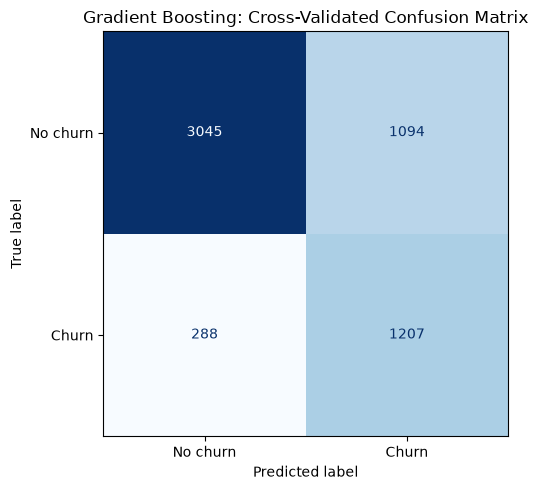

True negatives: 3045
False positives: 1094
False negatives: 288
True positives: 1207


In [9]:
oof_probabilities = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=get_cross_validation(),
    method="predict_proba",
    n_jobs=1
)[:, 1]

oof_predictions = (oof_probabilities >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_train, oof_predictions).ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    oof_predictions,
    display_labels=["No churn", "Churn"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Gradient Boosting: Cross-Validated Confusion Matrix")
fig.tight_layout()
confusion_matrix_path = FIGURE_DIR / "confusion_matrix.png"
fig.savefig(confusion_matrix_path, dpi=200, bbox_inches="tight")
plt.show()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

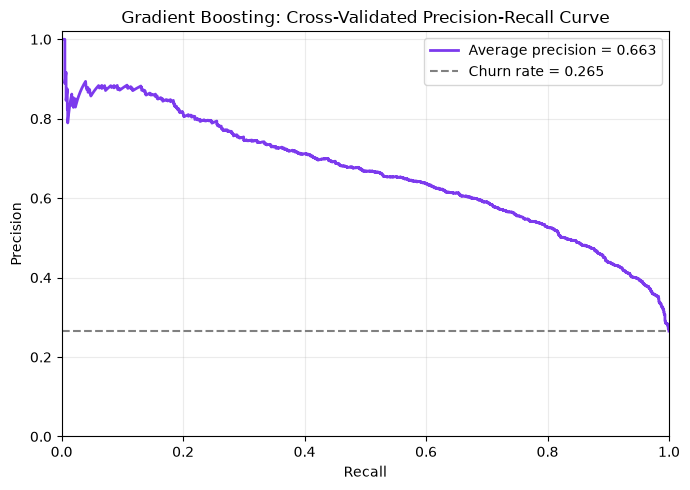

Average precision: 0.6635


In [10]:
precision_values, recall_values, _ = precision_recall_curve(
    y_train,
    oof_probabilities
)
average_precision = average_precision_score(y_train, oof_probabilities)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    recall_values,
    precision_values,
    color="#7C3AED",
    linewidth=2,
    label=f"Average precision = {average_precision:.3f}"
)
ax.axhline(
    y_train.mean(),
    color="gray",
    linestyle="--",
    label=f"Churn rate = {y_train.mean():.3f}"
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Gradient Boosting: Cross-Validated Precision-Recall Curve")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
precision_recall_path = FIGURE_DIR / "precision_recall_curve.png"
fig.savefig(precision_recall_path, dpi=200, bbox_inches="tight")
plt.show()

print("Average precision:", round(average_precision, 4))

The model correctly identified 1,207 churners and missed 288. It also predicted churn for 1,094 customers who did not churn. This matches the cross-validation results: recall is high, but precision is lower because the model produces more false churn alerts. The average precision of 0.6635 is above the training churn rate of 0.265.

## 7. Feature importance

Display the features used most often by the fitted Gradient Boosting model. These values show model importance, not cause and effect.

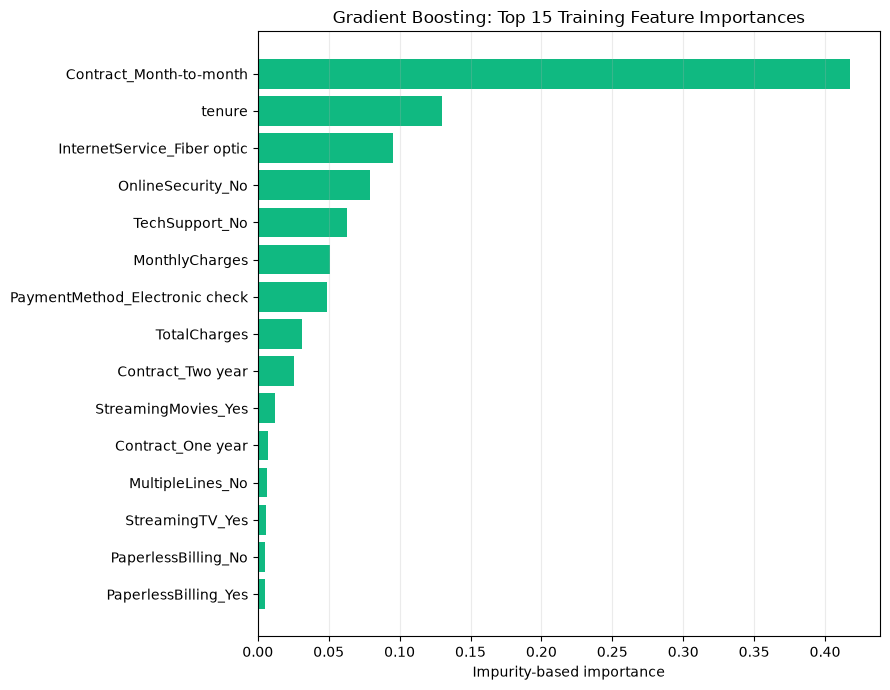

,Feature,Importance
0,Contract_Month-to-month,0.417861
1,tenure,0.129556
2,InternetService_Fiber optic,0.095443
3,OnlineSecurity_No,0.079443
4,TechSupport_No,0.062960
5,MonthlyCharges,0.050779
6,PaymentMethod_Electronic check,0.049064
7,TotalCharges,0.031024
8,Contract_Two year,0.025563
9,StreamingMovies_Yes,0.012344


Saved feature-importance figure to: C:\Users\sadee\Documents\Y3S1\ML\Project\New folder\IT3091_Telco_Churn--2\results\figures\gradient_boosting\feature_importance.png


In [11]:
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_pipeline.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

top_features = feature_importance.head(15).sort_values("Importance")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_features["Feature"], top_features["Importance"], color="#10B981")
ax.set_xlabel("Impurity-based importance")
ax.set_title("Gradient Boosting: Top 15 Training Feature Importances")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
importance_figure_path = FIGURE_DIR / "feature_importance.png"
fig.savefig(importance_figure_path, dpi=200, bbox_inches="tight")
plt.show()

display(feature_importance.head(15).reset_index(drop=True))
print("Saved feature-importance figure to:", importance_figure_path)